# Phân tích dữ liệu cơ bản (EDA) — Dataset Visuelle 2.0

**Visuelle 2.0** là bộ dữ liệu bán lẻ thời trang thực tế của chuỗi cửa hàng Nunalie (Ý), gồm 6 mùa (SS17 → AW19), 5.355 sản phẩm, 110 cửa hàng.

| File | Nội dung |
|---|---|
| `sales.csv` | Doanh số theo tuần (12 tuần đầu sau khi ra mắt) của từng sản phẩm × cửa hàng, kèm thuộc tính sản phẩm |
| `price_discount_series.csv` | Mức giảm giá theo 12 tuần và giá (đã chuẩn hóa) |
| `restocks.csv` | Các lần nhập thêm hàng (theo tuần/năm) |
| `customer_data.csv` | Giao dịch ở mức khách hàng (khách, cửa hàng, sản phẩm, thời điểm, số lượng) |
| `vis2_gtrends_data.csv` | Google Trends theo tuần cho danh mục / màu / chất liệu |
| `vis2_weather_data.csv` | Thời tiết theo ngày tại từng địa phương |
| `*.pt` | Từ điển nhãn (category/color/fabric) và ánh xạ cửa hàng → địa phương thời tiết |
| `stfore_*.csv` | Split train/test đã chuẩn hóa cho bài toán dự báo |
| `images/` | Ảnh sản phẩm |

**Mục tiêu notebook:** tổng quan chất lượng dữ liệu, phân phối các thuộc tính, xu hướng doanh số theo thời gian / mùa / danh mục / cửa hàng, ảnh hưởng của giá & giảm giá, hành vi khách hàng, và dữ liệu ngoại sinh (Google Trends, thời tiết).

## 1. Thiết lập & đọc dữ liệu

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from PIL import Image

DATA = Path('Data/extracted/visuelle2')
WEEKS = [str(i) for i in range(12)]

# Bảng màu cố định (categorical, đã kiểm tra an toàn cho người mù màu)
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
MAIN = PALETTE[0]
plt.rcParams.update({
    'figure.figsize': (11, 4.5), 'figure.dpi': 100,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#52514e', 'axes.labelcolor': '#0b0b0b',
    'axes.grid': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.prop_cycle': plt.cycler(color=PALETTE), 'lines.linewidth': 2,
    'axes.titleweight': 'bold', 'axes.titlesize': 12,
})
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', '{:,.3f}'.format)
from figure_style import apply_theme, PAL, SEASON_COLORS, COLOR_MAP, SEQ, ramp, finish_eda
apply_theme(journal=False)
PALETTE, MAIN = PAL, PAL[0]

# Apply the same visual polish to all rendered notebook figures.
_original_show = getattr(plt.show, '_original_show', plt.show)
def styled_show(*args, **kwargs):
    for number in plt.get_fignums():
        finish_eda(plt.figure(number))
    return _original_show(*args, **kwargs)
styled_show._original_show = _original_show
plt.show = styled_show

from figure_style import categorical_colors


In [2]:
sales     = pd.read_csv(DATA / 'sales.csv', index_col=0, parse_dates=['release_date'])
price     = pd.read_csv(DATA / 'price_discount_series.csv')
restocks  = pd.read_csv(DATA / 'restocks.csv')
# customer_data lớn (~3.2 triệu dòng) → khai báo kiểu dữ liệu gọn để tiết kiệm RAM
customers = pd.read_csv(DATA / 'customer_data.csv', parse_dates=['data'],
                        dtype={'customer': 'int32', 'retail': 'int16', 'external_code': 'int16', 'qty': 'int8'})
gtrends   = pd.read_csv(DATA / 'vis2_gtrends_data.csv', parse_dates=['date'])
weather   = pd.read_csv(DATA / 'vis2_weather_data.csv')
weather['date'] = pd.to_datetime(weather['date'], format='%d/%m/%Y')

tables = {'sales': sales, 'price_discount': price, 'restocks': restocks,
          'customers': customers, 'gtrends': gtrends, 'weather': weather}
pd.DataFrame({name: {'Số dòng': df.shape[0], 'Số cột': df.shape[1],
                     'Ô thiếu (NaN)': int(df.isna().sum().sum()),
                     'Dòng trùng lặp': int(df.duplicated().sum()),
                     'Bộ nhớ (MB)': round(df.memory_usage(deep=True).sum() / 1e6, 1)}
              for name, df in tables.items()}).T

,Số dòng,Số cột,Ô thiếu (NaN),Dòng trùng lặp,Bộ nhớ (MB)
sales,"106,850.000",21.000,0.000,0.000,49.400
price_discount,"106,850.000",15.000,1.000,0.000,12.800
restocks,"949,766.000",5.000,0.000,0.000,38.000
customers,"3,184,162.000",5.000,0.000,1.000,54.100
gtrends,220.000,97.000,0.000,0.000,0.200
weather,"89,071.000",14.000,"40,416.000",0.000,10.000


Các file nhãn `.pt` (PyTorch) chứa từ điển mã hóa; `shop_weather_pairs.pt` ánh xạ mã cửa hàng → mã địa phương trong dữ liệu thời tiết.

In [3]:
try:
    import torch
    labels = {f: torch.load(DATA / f'{f}.pt', weights_only=True)
              for f in ['category_labels', 'color_labels', 'fabric_labels', 'shop_weather_pairs']}
    for k, v in labels.items():
        print(f'{k:20s}: {len(v)} phần tử, ví dụ {list(v.items())[:4]}')
except ImportError:
    labels = None
    print('Chưa cài torch — bỏ qua các file .pt')

category_labels     : 31 phần tử, ví dụ [('culottes', 0), ('shorts', 1), ('drop sleeve', 2), ('long sleeve', 3)]
color_labels        : 10 phần tử, ví dụ [('grey', 0), ('white', 1), ('black', 2), ('green', 3)]
fabric_labels       : 59 phần tử, ví dụ [('polyviscous', 0), ('satin cotton', 1), ('technical', 2), ('crepe', 3)]
shop_weather_pairs  : 110 phần tử, ví dụ [(36, 78), (41, 71), (10, 8), (51, 113)]


## 2. Dữ liệu bán hàng (`sales.csv`)

In [4]:
sales.head()

,external_code,retail,season,category,color,image_path,fabric,release_date,restock,0,1,2,3,4,5,6,7,8,9,10,11
0,5,36,SS17,long sleeve,grey,PE17/00005.png,acrylic,2016-11-28,22,1.000,3.000,1.000,1.000,2.000,1.000,0.000,0.000,2.000,0.000,0.000,0.000
1,2,51,SS17,long sleeve,violet,PE17/00002.png,acrylic,2016-11-28,17,1.000,1.000,1.000,0.000,0.000,2.000,0.000,0.000,0.000,1.000,1.000,0.000
2,5,10,SS17,long sleeve,grey,PE17/00005.png,acrylic,2016-11-28,15,1.000,3.000,1.000,0.000,1.000,1.000,1.000,1.000,1.000,0.000,0.000,1.000
3,9,41,SS17,culottes,yellow,PE17/00009.png,scuba crepe,2016-11-28,32,1.000,1.000,1.000,1.000,0.000,0.000,0.000,1.000,0.000,1.000,0.000,0.000
4,5,13,SS17,long sleeve,grey,PE17/00005.png,acrylic,2016-11-28,26,1.000,2.000,4.000,0.000,3.000,0.000,2.000,1.000,0.000,0.000,0.000,0.000


In [5]:
sales['total_sales'] = sales[WEEKS].sum(axis=1)
sales.info()
sales[['restock', 'total_sales'] + WEEKS].describe().T

<class 'pandas.core.frame.DataFrame'>
Index: 106850 entries, 0 to 106849
Data columns (total 22 columns):
 #   Column         Non-Null Count   Dtype         
---  ------         --------------   -----         
 0   external_code  106850 non-null  int64         
 1   retail         106850 non-null  int64         
 2   season         106850 non-null  object        
 3   category       106850 non-null  object        
 4   color          106850 non-null  object        
 5   image_path     106850 non-null  object        
 6   fabric         106850 non-null  object        
 7   release_date   106850 non-null  datetime64[ns]
 8   restock        106850 non-null  int64         
 9   0              106850 non-null  float64       
 10  1              106850 non-null  float64       
 11  2              106850 non-null  float64       
 12  3              106850 non-null  float64       
 13  4              106850 non-null  float64       
 14  5              106850 non-null  float64       
 15  6    

,count,mean,std,min,25%,50%,75%,max
restock,"106,850.000",22.436,16.971,1.000,13.000,18.000,26.000,389.000
total_sales,"106,850.000",14.966,10.996,3.000,9.000,12.000,17.000,268.000
0,"106,850.000",1.825,1.252,0.000,1.000,1.000,2.000,25.000
1,"106,850.000",1.500,1.564,0.000,0.000,1.000,2.000,27.000
2,"106,850.000",1.448,1.577,0.000,0.000,1.000,2.000,27.000
3,"106,850.000",1.456,1.644,0.000,0.000,1.000,2.000,27.000
4,"106,850.000",1.424,1.681,-2.000,0.000,1.000,2.000,43.000
5,"106,850.000",1.410,1.758,-3.000,0.000,1.000,2.000,34.000
6,"106,850.000",1.344,1.779,0.000,0.000,1.000,2.000,49.000
7,"106,850.000",1.200,1.693,0.000,0.000,1.000,2.000,36.000


In [6]:
summary = pd.Series({
    'Số sản phẩm (external_code)': sales.external_code.nunique(),
    'Số cửa hàng (retail)': sales.retail.nunique(),
    'Số cặp sản phẩm × cửa hàng': len(sales),
    'Số danh mục': sales.category.nunique(),
    'Số màu': sales.color.nunique(),
    'Số chất liệu': sales.fabric.nunique(),
    'Ngày ra mắt sớm nhất': sales.release_date.min().date(),
    'Ngày ra mắt muộn nhất': sales.release_date.max().date(),
    'Tổng số lượng bán (12 tuần)': int(sales.total_sales.sum()),
    'Tỉ lệ cặp không bán được gì (%)': round((sales.total_sales == 0).mean() * 100, 2),
})
summary.to_frame('Giá trị')

,Giá trị
Số sản phẩm (external_code),5355
Số cửa hàng (retail),110
Số cặp sản phẩm × cửa hàng,106850
Số danh mục,27
Số màu,10
Số chất liệu,59
Ngày ra mắt sớm nhất,2016-11-28
Ngày ra mắt muộn nhất,2019-12-30
Tổng số lượng bán (12 tuần),1599100
Tỉ lệ cặp không bán được gì (%),0.000


In [7]:
# Kiểm tra chất lượng: giá trị bán âm theo tuần (nhiều khả năng là hàng trả lại)
neg = sales[WEEKS] < 0
print(f'Số ô bán âm: {int(neg.sum().sum()):,} trên {neg.size:,} ô ({neg.values.mean() * 100:.2f}%)')
print(f'Số cặp SP × cửa hàng có ít nhất 1 tuần âm: {int(neg.any(axis=1).sum()):,}')

Số ô bán âm: 3,386 trên 1,282,200 ô (0.26%)


Số cặp SP × cửa hàng có ít nhất 1 tuần âm: 3,358


### 2.1 Phân phối thuộc tính sản phẩm

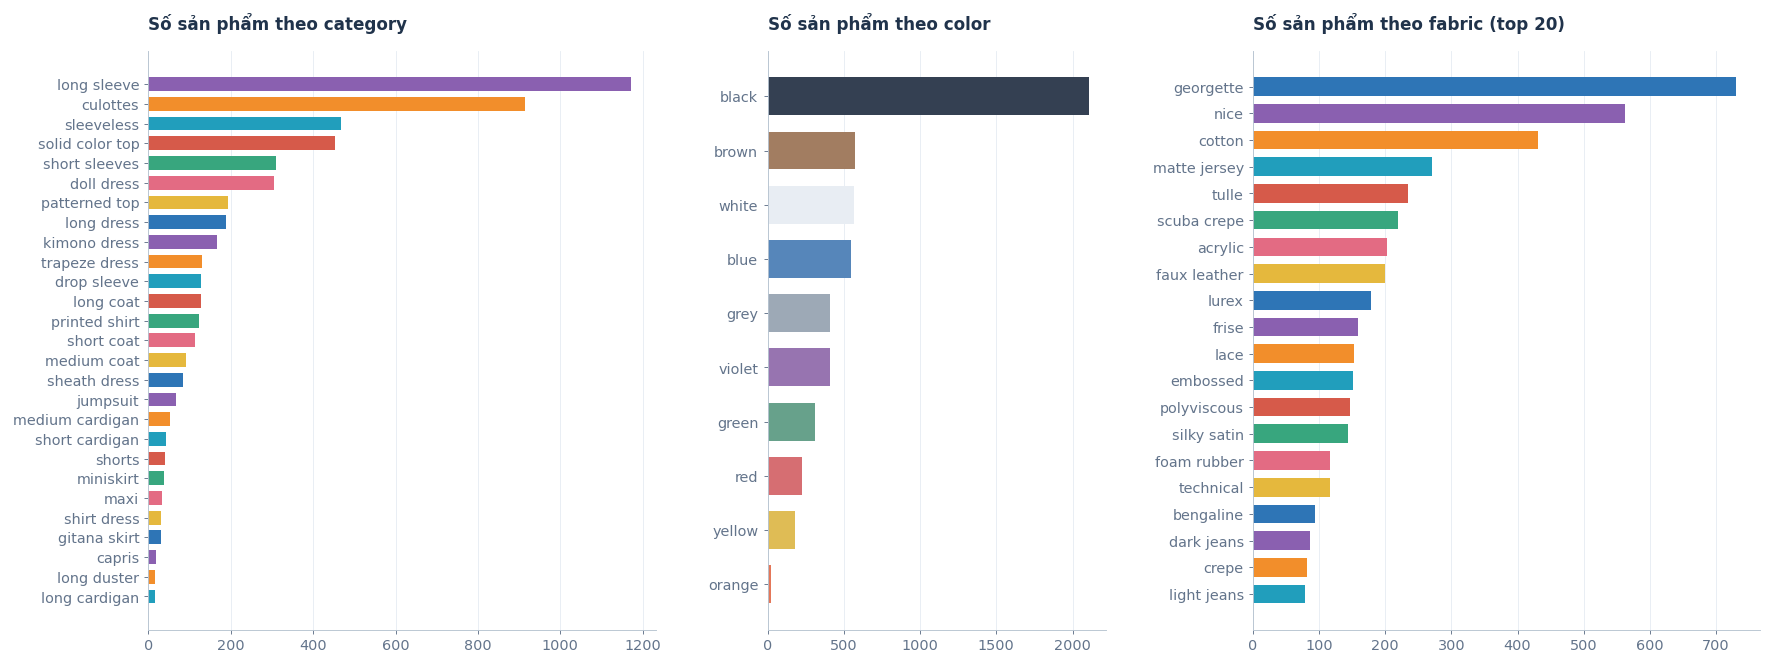

In [8]:
products = sales.drop_duplicates('external_code')
fig, axes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={'width_ratios': [1.2, 0.8, 1.2]})
for ax, col, n in zip(axes, ['category', 'color', 'fabric'], [27, 10, 20]):
    vc = products[col].value_counts().head(n).sort_values()
    ax.barh(vc.index, vc.values, color=[COLOR_MAP.get(c, MAIN) for c in vc.index] if col == 'color' else categorical_colors(len(vc)), height=0.7)
    ax.set_title(f'Số sản phẩm theo {col}' + (f' (top {n})' if col == 'fabric' else ''))
    ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

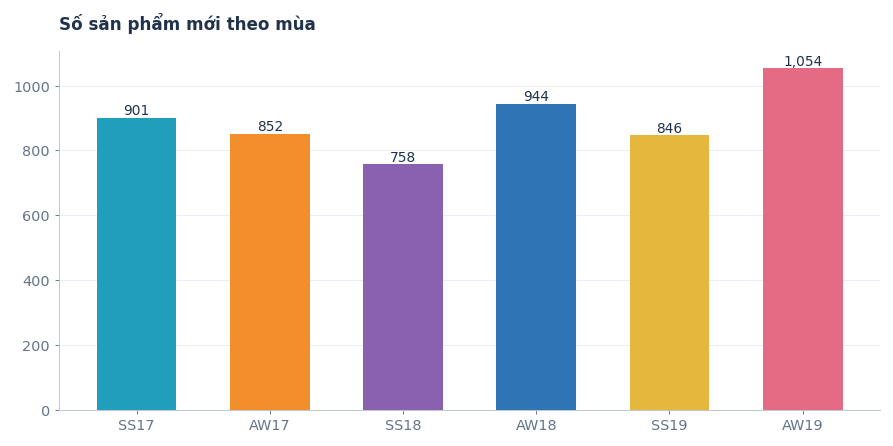

,products,rows,total_sales,stores
season,,,,
SS17,901,12948,"194,720.000",66
AW17,852,15742,"243,943.000",72
SS18,758,15974,"256,126.000",83
AW18,944,17859,"262,667.000",89
SS19,846,19684,"304,284.000",96
AW19,1054,24643,"337,360.000",105


In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
order = ['SS17', 'AW17', 'SS18', 'AW18', 'SS19', 'AW19']
season_stats = sales.groupby('season').agg(products=('external_code', 'nunique'),
                                           rows=('external_code', 'size'),
                                           total_sales=('total_sales', 'sum'),
                                           stores=('retail', 'nunique')).reindex(order)
ax.bar(season_stats.index, season_stats['products'], color=SEASON_COLORS, width=0.6)
for i, v in enumerate(season_stats['products']):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9)
ax.set_title('Số sản phẩm mới theo mùa'); ax.grid(axis='x', visible=False)
plt.show()
season_stats

> *SS = Spring/Summer (Xuân–Hè), AW = Autumn/Winter (Thu–Đông).*

### 2.2 Phân phối doanh số

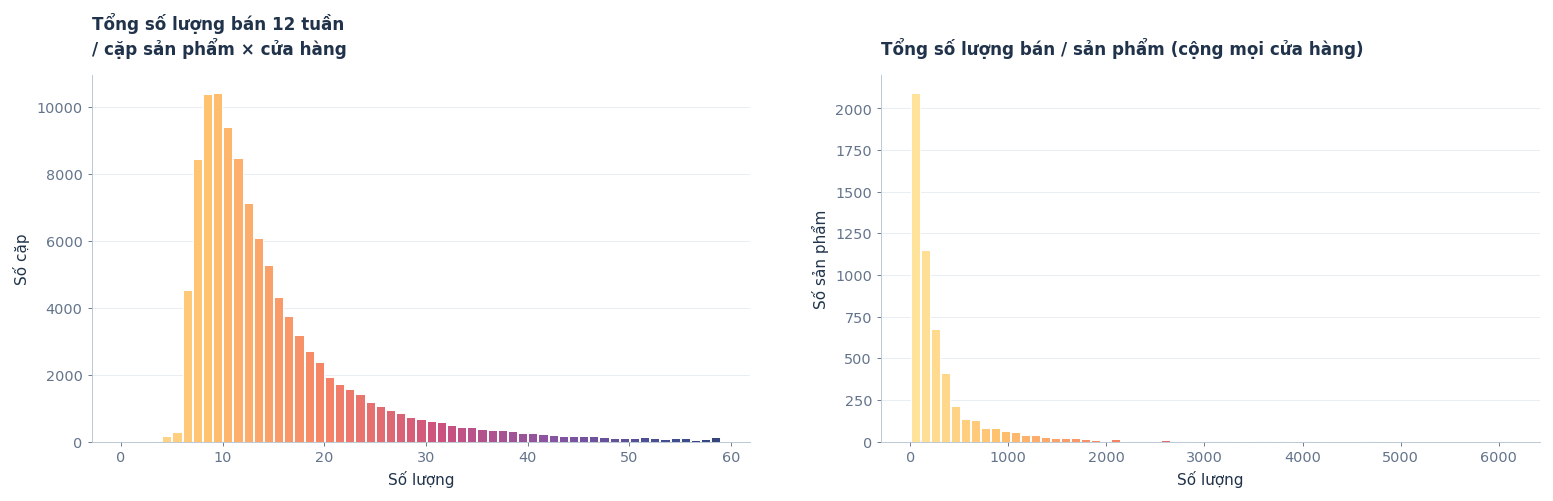

Doanh số / sản phẩm:
count   5,355.000
mean      298.600
std       445.500
min         5.000
25%        58.000
50%       152.000
75%       329.000
max     6,120.000


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(sales.total_sales, bins=range(0, 60), color=MAIN, rwidth=0.9)
axes[0].set_title('Tổng số lượng bán 12 tuần\n/ cặp sản phẩm × cửa hàng')
axes[0].set_xlabel('Số lượng'); axes[0].set_ylabel('Số cặp')

prod_sales = sales.groupby('external_code').total_sales.sum()
axes[1].hist(prod_sales, bins=60, color=MAIN, rwidth=0.9)
axes[1].set_title('Tổng số lượng bán / sản phẩm (cộng mọi cửa hàng)')
axes[1].set_xlabel('Số lượng'); axes[1].set_ylabel('Số sản phẩm')
plt.tight_layout(); plt.show()
print('Doanh số / sản phẩm:'); print(prod_sales.describe().round(1).to_string())

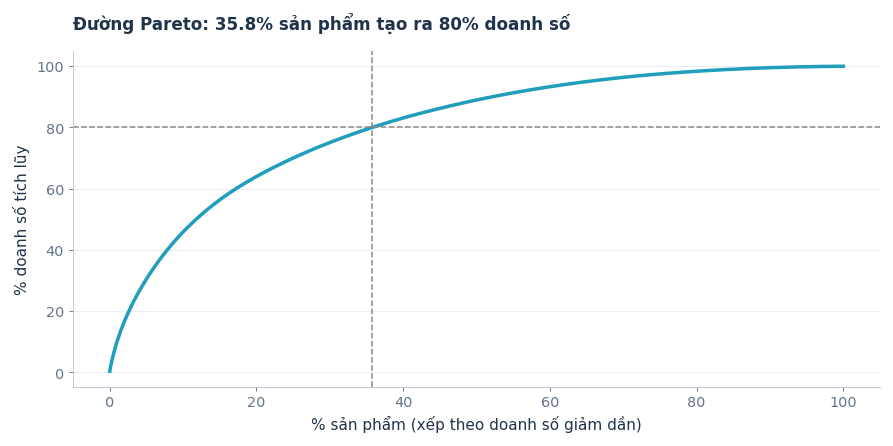

In [11]:
# Mức độ tập trung: bao nhiêu % sản phẩm tạo ra 80% doanh số (Pareto)
s = prod_sales.sort_values(ascending=False)
cum = s.cumsum() / s.sum()
share_80 = (cum <= 0.8).sum() / len(s) * 100

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(s) + 1) / len(s) * 100, cum.values * 100, color=MAIN)
ax.axhline(80, color='#8a8984', lw=1, ls='--'); ax.axvline(share_80, color='#8a8984', lw=1, ls='--')
ax.set_xlabel('% sản phẩm (xếp theo doanh số giảm dần)'); ax.set_ylabel('% doanh số tích lũy')
ax.set_title(f'Đường Pareto: {share_80:.1f}% sản phẩm tạo ra 80% doanh số')
plt.show()

### 2.3 Đường cong doanh số theo vòng đời (12 tuần đầu)

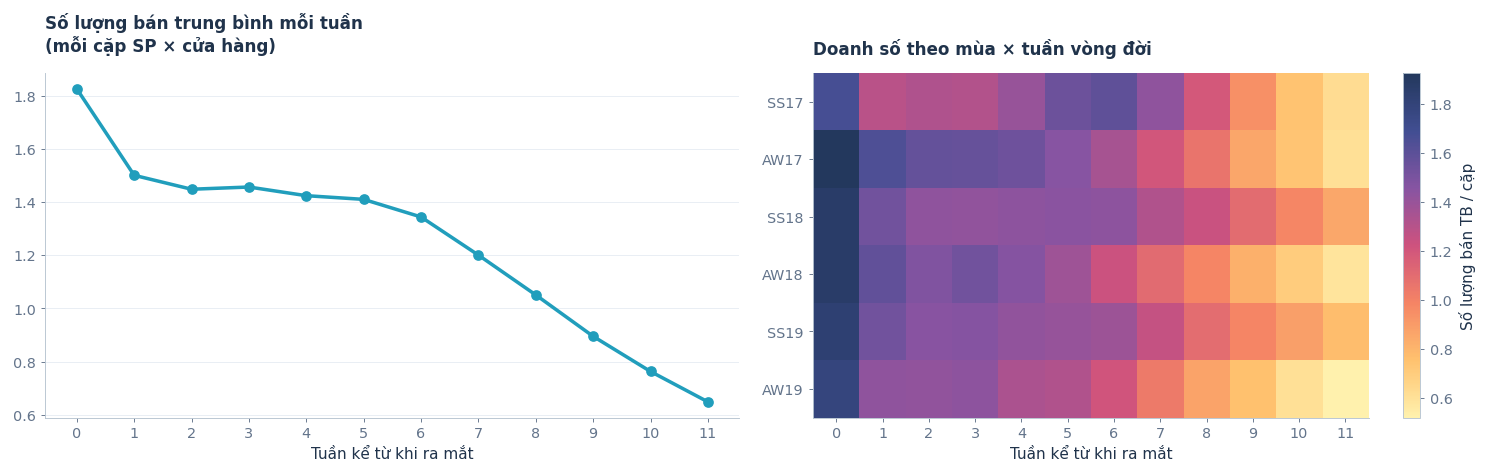

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
weekly = sales[WEEKS].mean()
axes[0].plot(range(12), weekly.values, marker='o', ms=6, color=MAIN)
axes[0].set_title('Số lượng bán trung bình mỗi tuần\n(mỗi cặp SP × cửa hàng)')
axes[0].set_xlabel('Tuần kể từ khi ra mắt'); axes[0].set_xticks(range(12))

life = sales.groupby('season')[WEEKS].mean().reindex(order)
im = axes[1].imshow(life.values, cmap=SEQ, aspect='auto')
axes[1].set_yticks(range(6), order); axes[1].set_xticks(range(12), range(12))
axes[1].set_title('Doanh số theo mùa × tuần vòng đời'); axes[1].set_xlabel('Tuần kể từ khi ra mắt')
axes[1].grid(False)
fig.colorbar(im, ax=axes[1], label='Số lượng bán TB / cặp')
plt.tight_layout(); plt.show()

### 2.4 Doanh số theo thời gian (lịch)

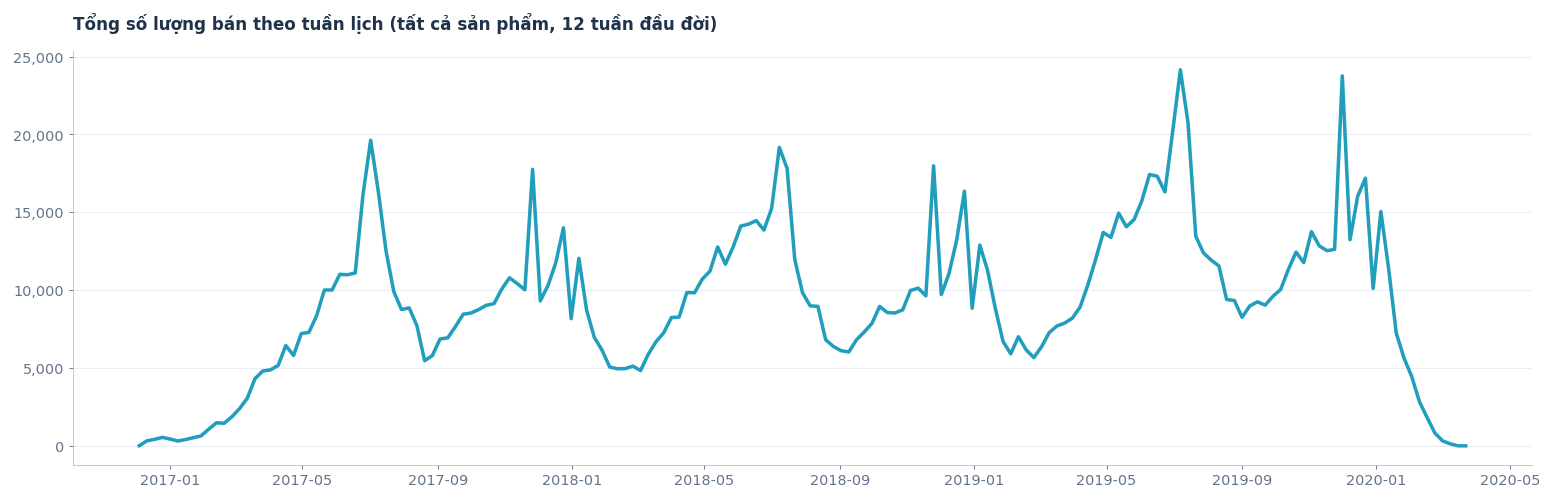

In [13]:
# Chuyển 12 tuần tương đối về tuần lịch thực tế: ngày = release_date + k tuần
long = sales[['external_code', 'retail', 'release_date'] + WEEKS].melt(
    id_vars=['external_code', 'retail', 'release_date'], var_name='week', value_name='qty')
long['date'] = long.release_date + pd.to_timedelta(long.week.astype(int) * 7, unit='D')
cal = long.groupby(pd.Grouper(key='date', freq='W')).qty.sum()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(cal.index, cal.values, color=MAIN)
ax.set_title('Tổng số lượng bán theo tuần lịch (tất cả sản phẩm, 12 tuần đầu đời)')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
plt.show()

### 2.5 Doanh số theo danh mục, màu, chất liệu

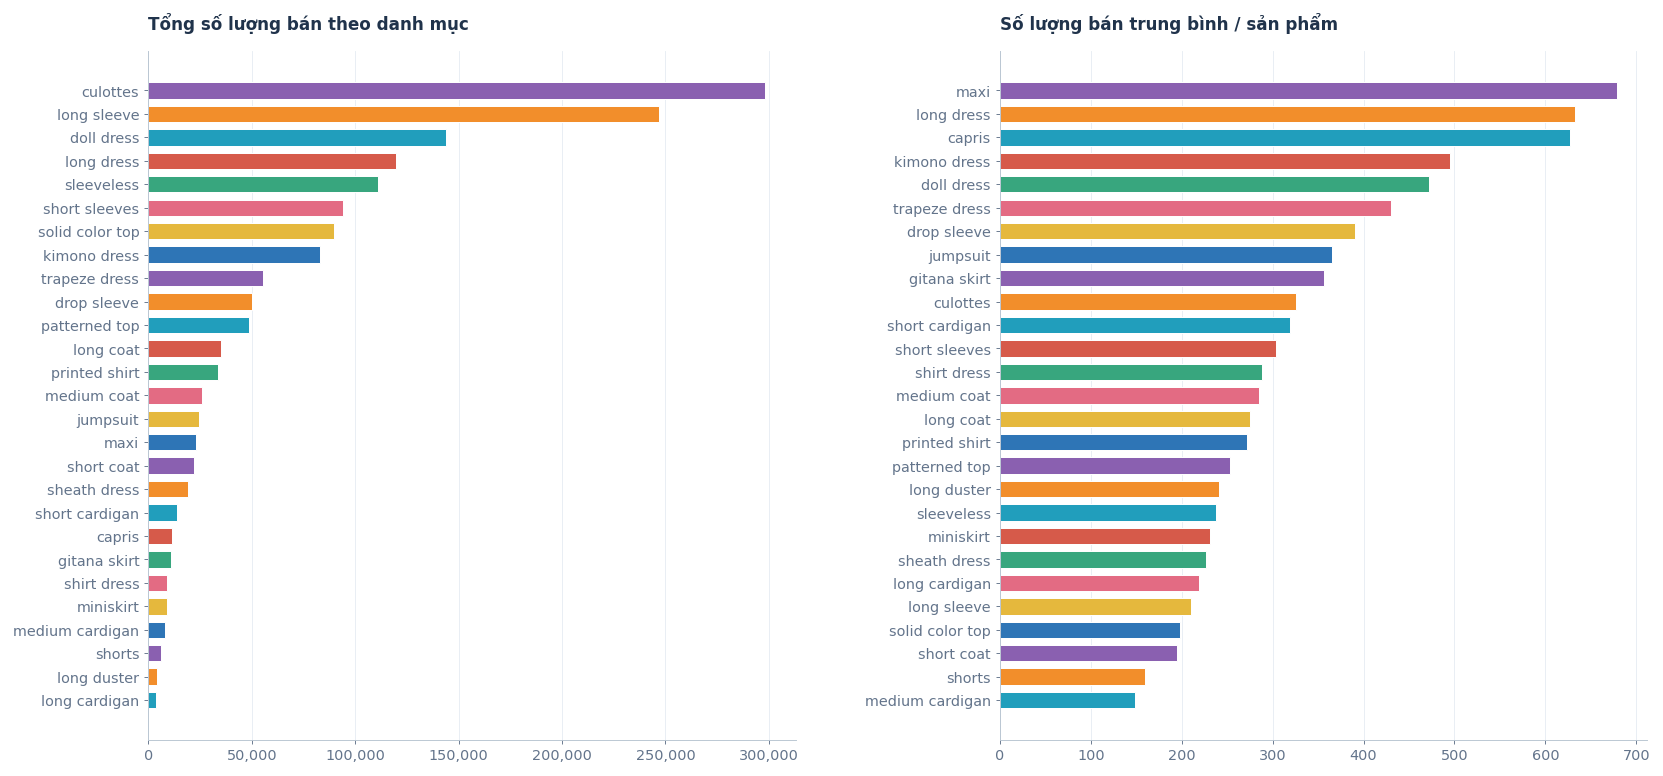

,products,total,mean_per_store,per_product
category,,,,
culottes,915,"298,208.000",14.928,325.910
long sleeve,1173,"247,083.000",12.629,210.642
doll dress,305,"143,994.000",17.349,472.111
long dress,189,"119,658.000",20.155,633.111
sleeveless,468,"111,068.000",13.751,237.325
short sleeves,310,"94,227.000",15.139,303.958
solid color top,453,"89,669.000",13.747,197.945
kimono dress,167,"82,734.000",18.667,495.413
trapeze dress,129,"55,471.000",16.764,430.008


In [14]:
def perf(col):
    g = sales.groupby(col).agg(products=('external_code', 'nunique'),
                               total=('total_sales', 'sum'),
                               mean_per_store=('total_sales', 'mean'))
    g['per_product'] = g.total / g.products
    return g.sort_values('total', ascending=False)

cat_perf = perf('category')
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
c = cat_perf.total.sort_values()
axes[0].barh(c.index, c.values, color=MAIN, height=0.7); axes[0].set_title('Tổng số lượng bán theo danh mục')
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
c = cat_perf.per_product.sort_values()
axes[1].barh(c.index, c.values, color=PALETTE[1], height=0.7); axes[1].set_title('Số lượng bán trung bình / sản phẩm')
for ax in axes: ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
cat_perf.head(10)

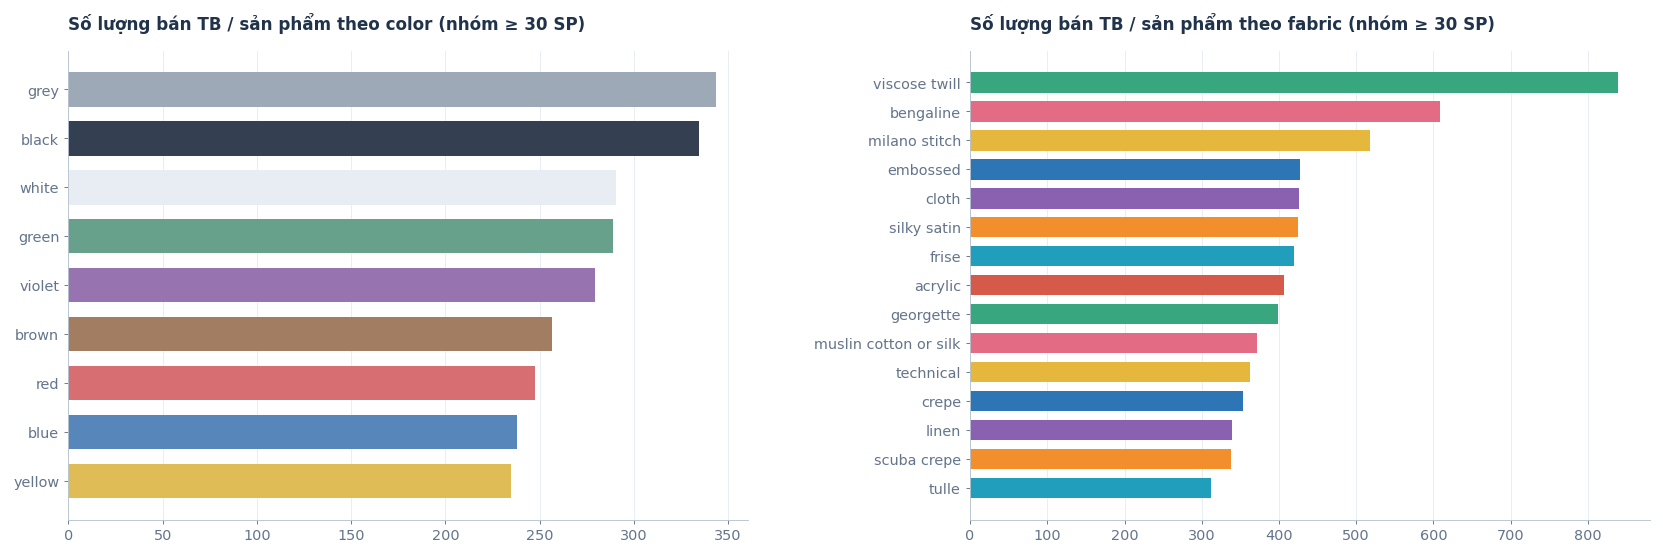

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, col in zip(axes, ['color', 'fabric']):
    p = perf(col)
    p = p[p.products >= 30].per_product.sort_values().tail(15)  # chỉ nhóm có >= 30 sản phẩm
    ax.barh(p.index, p.values, color=[COLOR_MAP[c] for c in p.index] if col == 'color' else categorical_colors(len(p)), height=0.7)
    ax.set_title(f'Số lượng bán TB / sản phẩm theo {col} (nhóm ≥ 30 SP)')
    ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

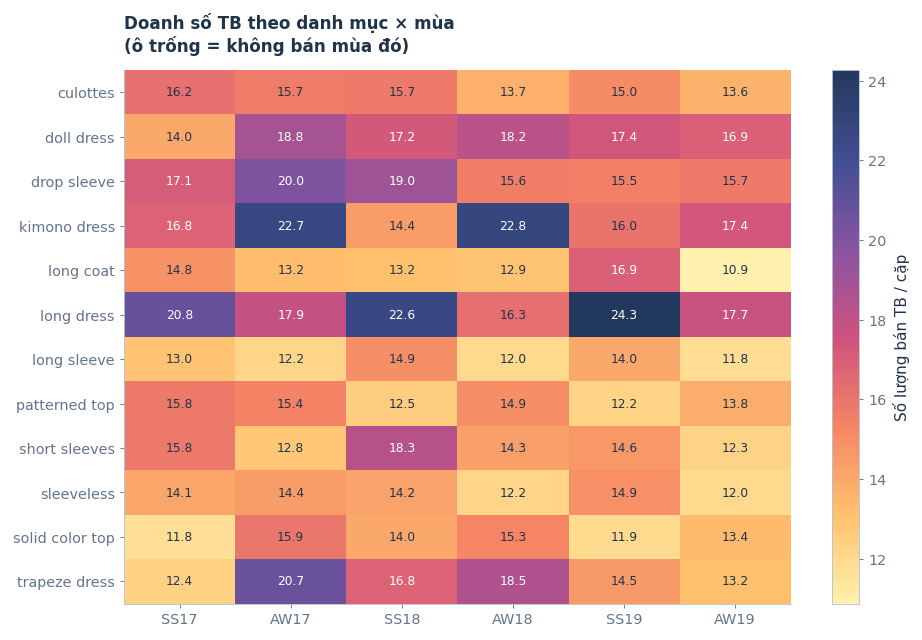

In [16]:
# Heatmap: số lượng bán TB / cặp SP × cửa hàng theo danh mục × mùa (top 12 danh mục)
top_cats = cat_perf.head(12).index
pv = sales[sales.category.isin(top_cats)].pivot_table(index='category', columns='season',
                                                      values='total_sales', aggfunc='mean')[order]
fig, ax = plt.subplots(figsize=(9, 6))
im = ax.imshow(pv.values, cmap=SEQ, aspect='auto')
ax.set_xticks(range(len(order)), order); ax.set_yticks(range(len(pv)), pv.index); ax.grid(False)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        v = pv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=8,
                    color='white' if np.dot(im.cmap(im.norm(v))[:3], [.2126, .7152, .0722]) < .52 else '#20334B')
plt.colorbar(im, ax=ax, label='Số lượng bán TB / cặp')
ax.set_title('Doanh số TB theo danh mục × mùa\n(ô trống = không bán mùa đó)')
plt.show()

### 2.6 Hiệu quả theo cửa hàng

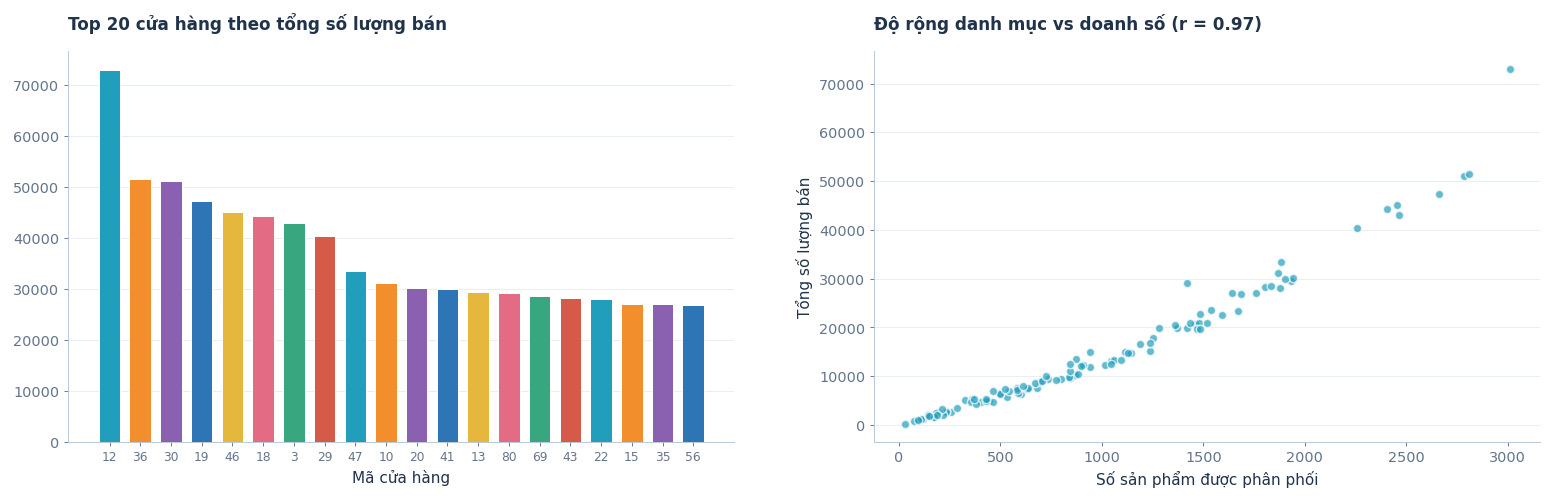

,count,mean,std,min,25%,50%,75%,max
products,110.000,971.364,708.478,27.000,410.500,842.000,"1,453.750","3,010.000"
total,110.000,"14,537.273","13,288.183",246.000,"5,009.500","10,119.000","20,722.500","73,049.000"
per_product,110.000,13.590,2.485,7.813,11.939,13.261,14.971,24.269


In [17]:
store = sales.groupby('retail').agg(products=('external_code', 'nunique'), total=('total_sales', 'sum'))
store['per_product'] = store.total / store.products
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
top = store.total.sort_values(ascending=False).head(20)
axes[0].bar(top.index.astype(str), top.values, color=MAIN, width=0.7)
axes[0].set_title('Top 20 cửa hàng theo tổng số lượng bán'); axes[0].set_xlabel('Mã cửa hàng')
axes[0].grid(axis='x', visible=False); axes[0].tick_params(axis='x', labelsize=8)
axes[1].scatter(store.products, store.total, s=30, color=MAIN, alpha=0.7, edgecolor='white')
axes[1].set_xlabel('Số sản phẩm được phân phối'); axes[1].set_ylabel('Tổng số lượng bán')
axes[1].set_title(f'Độ rộng danh mục vs doanh số (r = {store.products.corr(store.total):.2f})')
plt.tight_layout(); plt.show()
store.describe().T

### 2.7 Nhập thêm hàng (restock) ban đầu

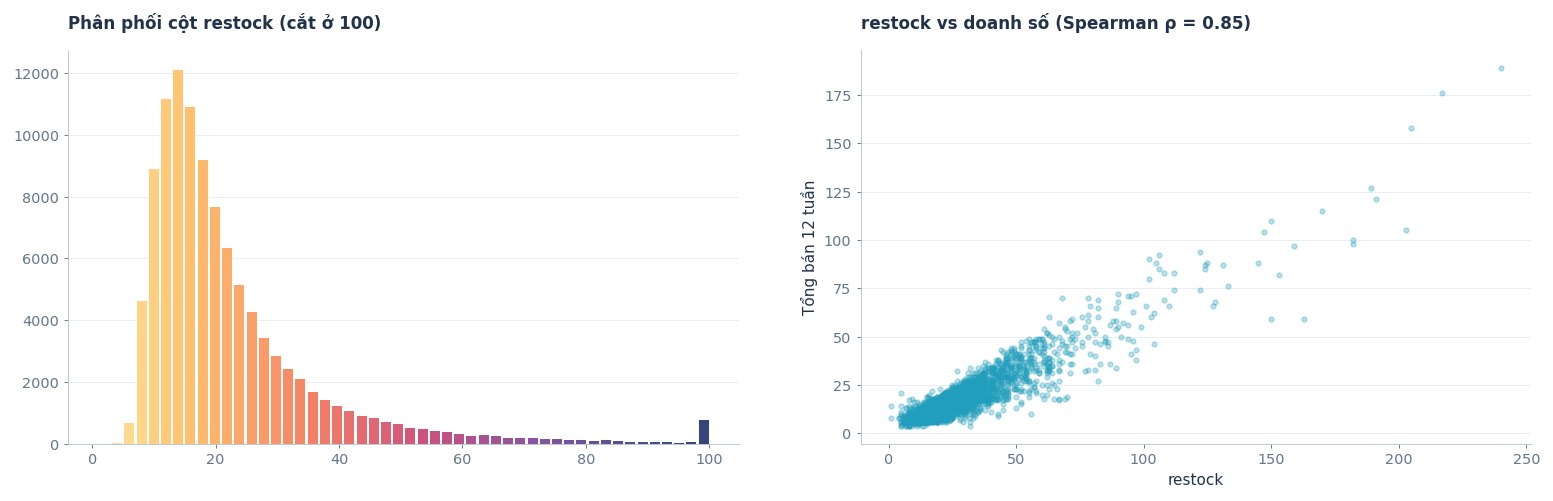

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(sales.restock.clip(upper=100), bins=50, color=MAIN, rwidth=0.9)
axes[0].set_title('Phân phối cột restock (cắt ở 100)')
sample = sales.sample(5000, random_state=0)
axes[1].scatter(sample.restock, sample.total_sales, s=10, alpha=0.3, color=MAIN)
axes[1].set_xlabel('restock'); axes[1].set_ylabel('Tổng bán 12 tuần')
axes[1].set_title(f'restock vs doanh số (Spearman ρ = {sales.restock.corr(sales.total_sales, method="spearman"):.2f})')
plt.tight_layout(); plt.show()

## 3. Giá & giảm giá (`price_discount_series.csv`)

In [19]:
price.head()

,external_code,retail,0,1,2,3,4,5,6,7,8,9,10,11,price
0,5,36,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.055
1,2,51,0.500,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.200,0.200,0.055
2,5,10,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.055
3,9,41,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.044
4,5,13,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.055


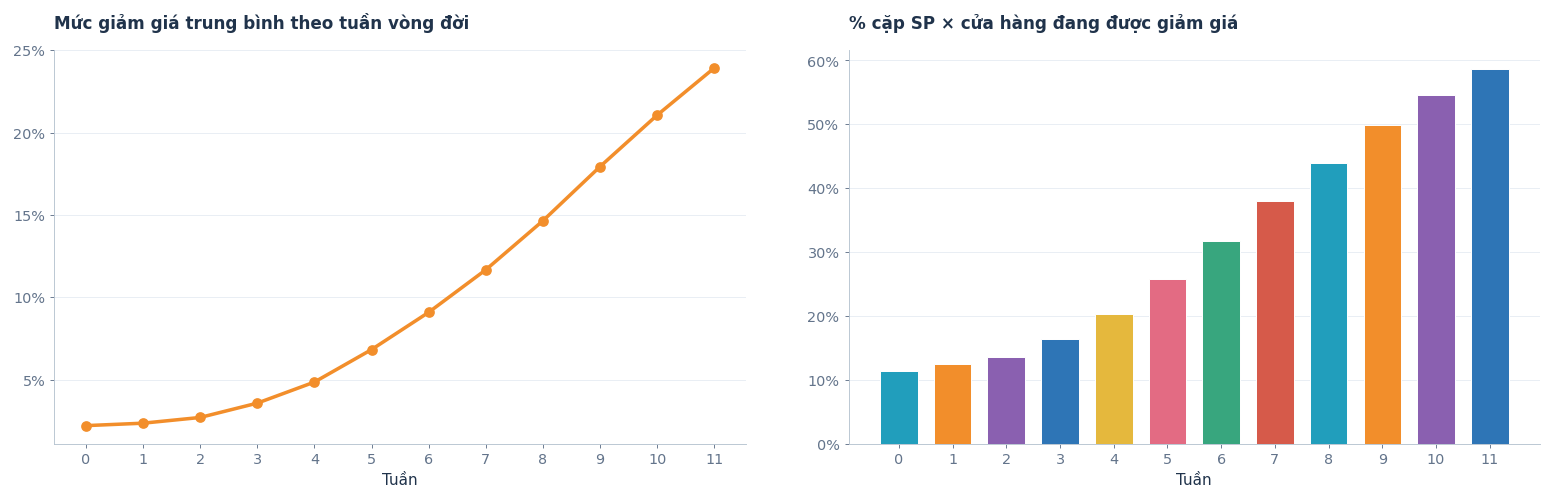

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
disc = price[WEEKS].mean() * 100
axes[0].plot(range(12), disc.values, marker='o', ms=6, color=PALETTE[1])
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[0].set_title('Mức giảm giá trung bình theo tuần vòng đời'); axes[0].set_xlabel('Tuần'); axes[0].set_xticks(range(12))
pct_disc = (price[WEEKS] > 0).mean() * 100
axes[1].bar(range(12), pct_disc.values, color=MAIN, width=0.7)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
axes[1].set_title('% cặp SP × cửa hàng đang được giảm giá'); axes[1].set_xlabel('Tuần'); axes[1].set_xticks(range(12))
axes[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

Số dòng sau merge: 106850 | thiếu giá: 0


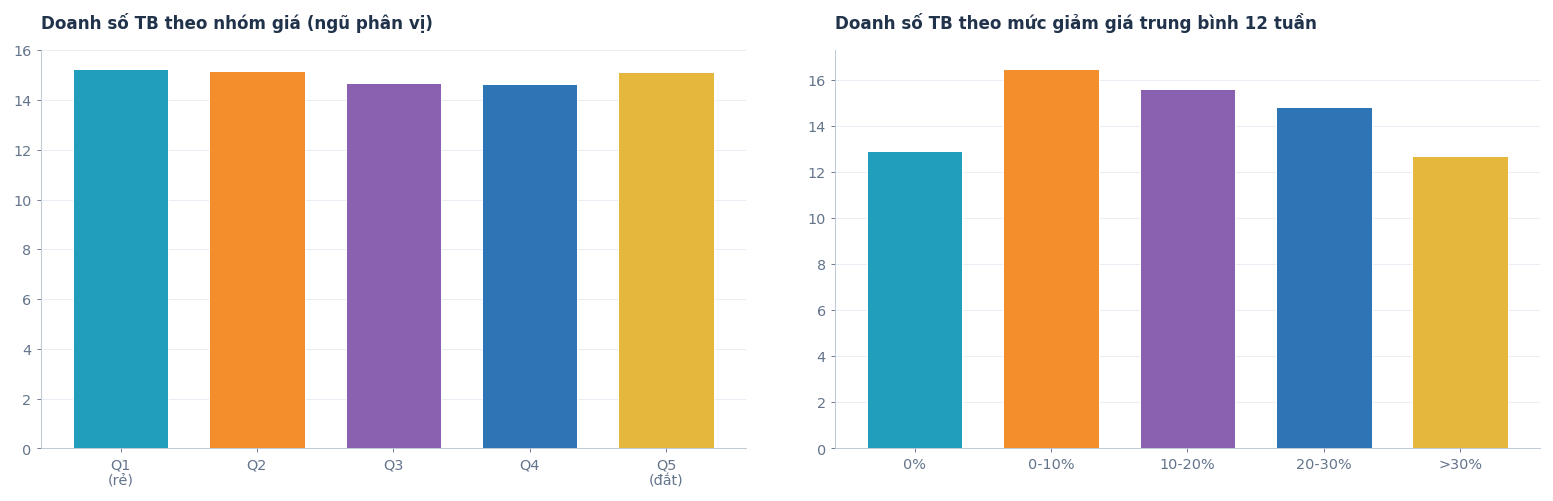

In [21]:
# Ghép giá/giảm giá với doanh số
pr = price.rename(columns={w: f'disc_{w}' for w in WEEKS})
sp = sales.merge(pr, on=['external_code', 'retail'], how='left')
print('Số dòng sau merge:', len(sp), '| thiếu giá:', sp.price.isna().sum())

sp['avg_disc'] = sp[[f'disc_{w}' for w in WEEKS]].mean(axis=1)
sp['price_bin'] = pd.qcut(sp.price, 5, duplicates='drop')
sp['disc_bin'] = pd.cut(sp.avg_disc, [-0.01, 0, 0.1, 0.2, 0.3, 1], labels=['0%', '0-10%', '10-20%', '20-30%', '>30%'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
g = sp.groupby('price_bin', observed=True).total_sales.mean()
axes[0].bar(range(len(g)), g.values, color=MAIN, width=0.7)
axes[0].set_xticks(range(len(g)), ['Q1\n(rẻ)', 'Q2', 'Q3', 'Q4', 'Q5\n(đắt)'][:len(g)])
axes[0].set_title('Doanh số TB theo nhóm giá (ngũ phân vị)'); axes[0].grid(axis='x', visible=False)
g = sp.groupby('disc_bin', observed=True).total_sales.mean()
axes[1].bar(g.index.astype(str), g.values, color=PALETTE[1], width=0.7)
axes[1].set_title('Doanh số TB theo mức giảm giá trung bình 12 tuần'); axes[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

In [22]:
# Tương quan theo tuần: mức giảm giá tuần k vs số lượng bán tuần k
corr_w = [sp[f'disc_{w}'].corr(sp[w], method='spearman') for w in WEEKS]
pd.Series(corr_w, index=[f'tuần {w}' for w in WEEKS], name='Spearman(giảm giá, bán)').to_frame().T

,tuần 0,tuần 1,tuần 2,tuần 3,tuần 4,tuần 5,tuần 6,tuần 7,tuần 8,tuần 9,tuần 10,tuần 11
"Spearman(giảm giá, bán)",0.124,0.076,0.071,0.086,0.095,0.122,0.140,0.136,0.150,0.180,0.198,0.193


> Lưu ý: tương quan ở đây **không phải quan hệ nhân quả** — sản phẩm bán chậm thường bị giảm giá sâu hơn (nhân quả ngược).

## 4. Nhập hàng bổ sung (`restocks.csv`)

Phân bố năm:
year
2016      4494
2017    248787
2018    284861
2019    390901
2020     15485
2021      5237
2022         1


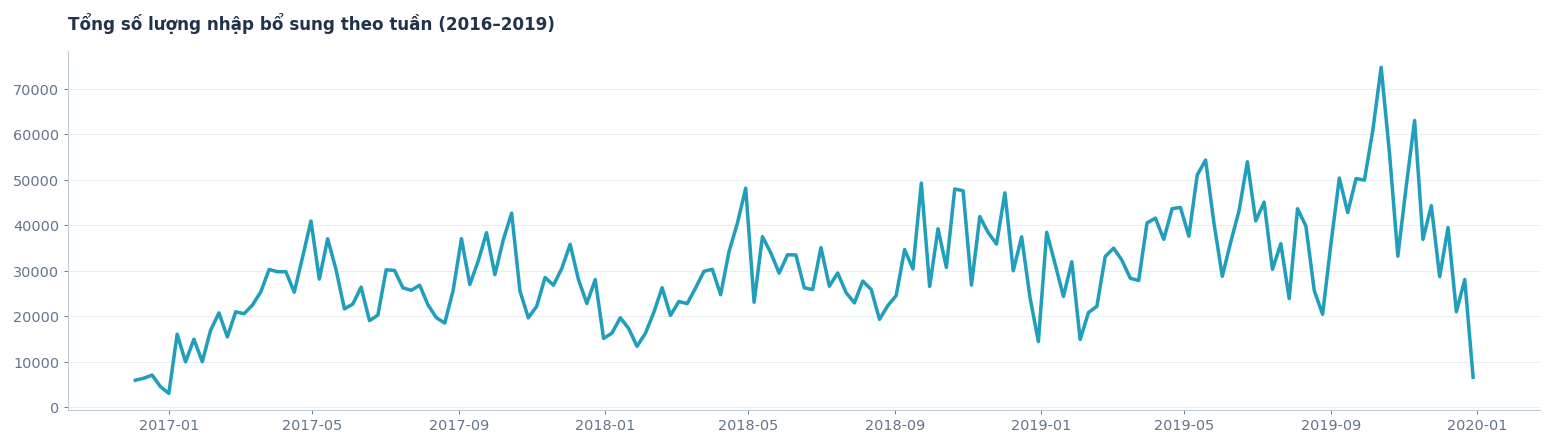

count   949,766.000
mean          5.205
std           3.832
min           1.000
25%           2.000
50%           5.000
75%           7.000
max         104.000
Name: qty, dtype: float64

In [23]:
restocks['date'] = pd.to_datetime(restocks.year.astype(str) + '-' + restocks.week.astype(str).str.zfill(2) + '-1',
                                  format='%G-%V-%u', errors='coerce')
print('Phân bố năm:'); print(restocks.year.value_counts().sort_index().to_string())
r = restocks[restocks.year <= 2019].groupby(pd.Grouper(key='date', freq='W')).qty.sum()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(r.index, r.values, color=MAIN)
ax.set_title('Tổng số lượng nhập bổ sung theo tuần (2016–2019)')
plt.show()
restocks.qty.describe()

> Có một số bản ghi năm > 2019 (đến 2022) — nằm ngoài giai đoạn bán của dataset, nên xem là ngoại lệ / cần kiểm tra khi dùng.

## 5. Dữ liệu khách hàng (`customer_data.csv`)

In [24]:
customers.head()

,customer,retail,external_code,data,qty
0,1,0,940,2017-06-10 12:41:57,1
1,1,0,718,2017-06-10 12:41:57,1
2,1,0,825,2017-06-10 12:54:11,1
3,2,1,471,2017-08-03 11:37:27,1
4,2,1,613,2017-08-03 11:37:27,1


In [25]:
cust = pd.Series({
    'Số giao dịch (dòng)': len(customers),
    'Số khách hàng': customers.customer.nunique(),
    'Số cửa hàng': customers.retail.nunique(),
    'Số sản phẩm': customers.external_code.nunique(),
    'Từ ngày': customers.data.min(),
    'Đến ngày': customers.data.max(),
    'Tổng số lượng': customers.qty.sum(),
    '% dòng qty = 1': round((customers.qty == 1).mean() * 100, 2),
})
cust.to_frame('Giá trị')

,Giá trị
Số giao dịch (dòng),3184162
Số khách hàng,665285
Số cửa hàng,129
Số sản phẩm,5577
Từ ngày,2016-12-01 17:58:46
Đến ngày,2021-06-24 11:10:42
Tổng số lượng,3232399
% dòng qty = 1,98.520


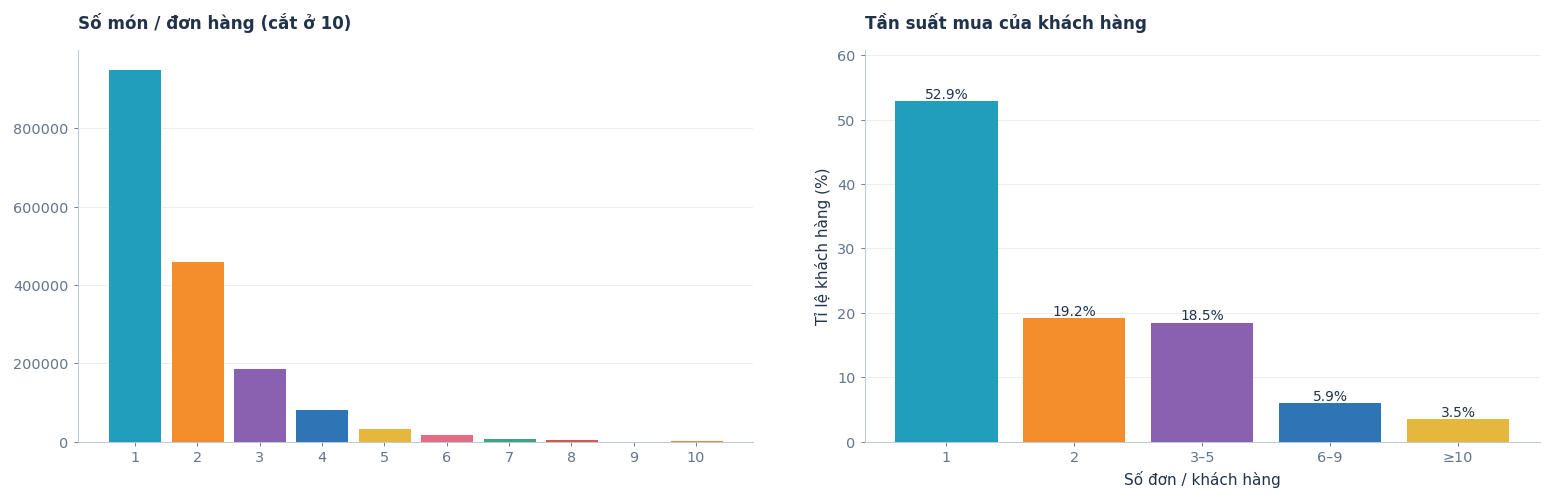

Số đơn: 1,757,698 | Món TB/đơn: 1.84 | % khách chỉ mua 1 lần: 52.9%


In [26]:
# Một "đơn hàng" (giỏ) = cùng khách, cùng cửa hàng, cùng thời điểm
orders = customers.groupby(['customer', 'retail', 'data'], sort=False).qty.sum().rename('items').reset_index()
per_cust = orders.groupby('customer').agg(n_orders=('data', 'size'), items=('items', 'sum'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(orders['items'].clip(upper=10), bins=np.arange(0.5, 11.5), color=MAIN, rwidth=0.85)
axes[0].set_title('Số món / đơn hàng (cắt ở 10)'); axes[0].set_xticks(range(1, 11))
axes[0].grid(axis='x', visible=False)
freq = pd.cut(per_cust.n_orders, [0,1,2,5,9,np.inf], labels=['1','2','3–5','6–9','≥10'])
counts = freq.value_counts(sort=False) / len(per_cust) * 100
axes[1].bar(counts.index.astype(str), counts.values, color=categorical_colors(len(counts)))
axes[1].set_title('Tần suất mua của khách hàng'); axes[1].set_xlabel('Số đơn / khách hàng')
axes[1].set_ylabel('Tỉ lệ khách hàng (%)')
for i,v in enumerate(counts): axes[1].text(i,v,f'{v:.1f}%',ha='center',va='bottom',fontsize=9)
axes[1].margins(y=.15); axes[1].grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print(f'Số đơn: {len(orders):,} | Món TB/đơn: {orders["items"].mean():.2f} | '
      f'% khách chỉ mua 1 lần: {(per_cust.n_orders == 1).mean() * 100:.1f}%')

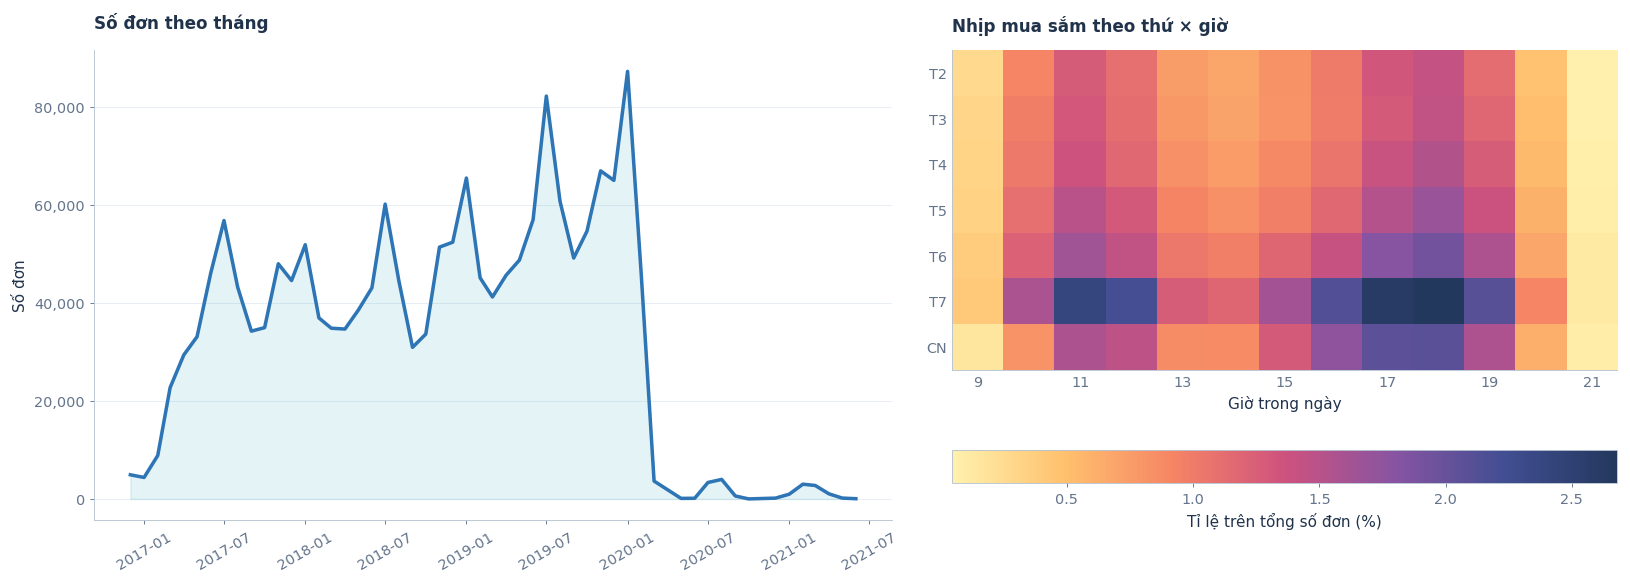

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.2, 1]})
m = orders.groupby(orders.data.dt.to_period('M')).size()
axes[0].plot(m.index.to_timestamp(), m.values, color=PALETTE[3])
axes[0].fill_between(m.index.to_timestamp(), 0, m.values, color=PALETTE[0], alpha=.12)
axes[0].set_title('Số đơn theo tháng'); axes[0].set_ylabel('Số đơn')
axes[0].tick_params(axis='x', rotation=30)
axes[0].yaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
# Combine weekday and hourly marginals into one joint view.
hours = range(9, 22)
shopping = pd.crosstab(orders.data.dt.dayofweek, orders.data.dt.hour, normalize='all') * 100
shopping = shopping.reindex(index=range(7), columns=hours, fill_value=0)
im = axes[1].imshow(shopping.values, cmap=SEQ, aspect='auto')
axes[1].set_yticks(range(7), ['T2','T3','T4','T5','T6','T7','CN'])
axes[1].set_xticks(range(0,13,2), list(hours)[::2]); axes[1].set_xlabel('Giờ trong ngày')
axes[1].set_title('Nhịp mua sắm theo thứ × giờ'); axes[1].grid(False); axes[1].tick_params(length=0)
fig.colorbar(im, ax=axes[1], orientation='horizontal', pad=.17, label='Tỉ lệ trên tổng số đơn (%)')
plt.show()


In [28]:
# Kiểm tra độ khớp: tổng qty trong customer_data so với sales (12 tuần đầu)
print(f'Tổng qty customer_data: {customers.qty.sum():,}')
print(f'Tổng qty sales (12 tuần đầu): {int(sales.total_sales.sum()):,}')
print('SP chỉ có trong customer_data:', len(set(customers.external_code) - set(sales.external_code)))
print('Cửa hàng chỉ có trong customer_data:', len(set(customers.retail) - set(sales.retail)))
print(f'% giao dịch từ 2020 trở đi: {(customers.data >= "2020-01-01").mean() * 100:.1f}%')
print('=> customer_data trải dài hơn (đến 2021) và phủ nhiều SP/cửa hàng hơn sales.csv (vốn chỉ ghi 12 tuần đầu), nên tổng lớn hơn.')

Tổng qty customer_data: 3,232,399
Tổng qty sales (12 tuần đầu): 1,599,100
SP chỉ có trong customer_data: 222


Cửa hàng chỉ có trong customer_data: 19
% giao dịch từ 2020 trở đi: 8.3%
=> customer_data trải dài hơn (đến 2021) và phủ nhiều SP/cửa hàng hơn sales.csv (vốn chỉ ghi 12 tuần đầu), nên tổng lớn hơn.


## 6. Google Trends (`vis2_gtrends_data.csv`)

(220, 97) 2015-10-05 → 2019-12-16


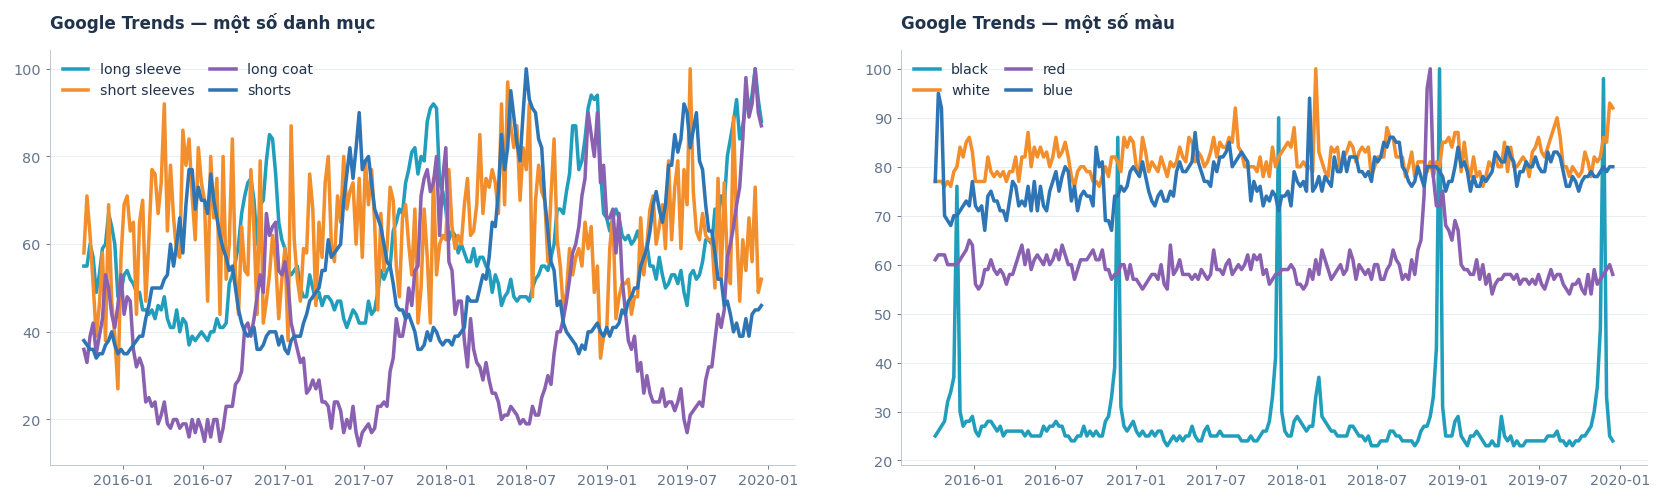

In [29]:
print(gtrends.shape, gtrends.date.min().date(), '→', gtrends.date.max().date())
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for i, c in enumerate(['long sleeve', 'short sleeves', 'long coat', 'shorts']):
    axes[0].plot(gtrends.date, gtrends[c], label=c, color=PALETTE[i])
axes[0].set_title('Google Trends — một số danh mục'); axes[0].legend(frameon=False, ncol=2)
for i, c in enumerate(['black', 'white', 'red', 'blue']):
    axes[1].plot(gtrends.date, gtrends[c], label=c, color=PALETTE[i])
axes[1].set_title('Google Trends — một số màu'); axes[1].legend(frameon=False, ncol=2)
plt.tight_layout(); plt.show()

Rõ ràng có **tính mùa vụ**: áo khoác dài tăng vào mùa đông, quần short / áo cộc tay tăng vào mùa hè — tín hiệu hữu ích làm biến ngoại sinh cho dự báo.

## 7. Thời tiết (`vis2_weather_data.csv`)

Số địa phương: 61 | 2016-01-01 → 2019-12-31
Tỉ lệ thiếu theo cột (%):
locality          0.000
date              0.000
avg temp °C       3.780
min temp °C       3.780
max temp °C       3.780
dew point °C      3.780
humidity %        3.780
visibility km     3.780
avg wind km/h     3.780
max wind km/h     3.780
gust km/h         3.780
slm pressure mb   3.780
avg pressure mb   3.780
rain mm           3.780


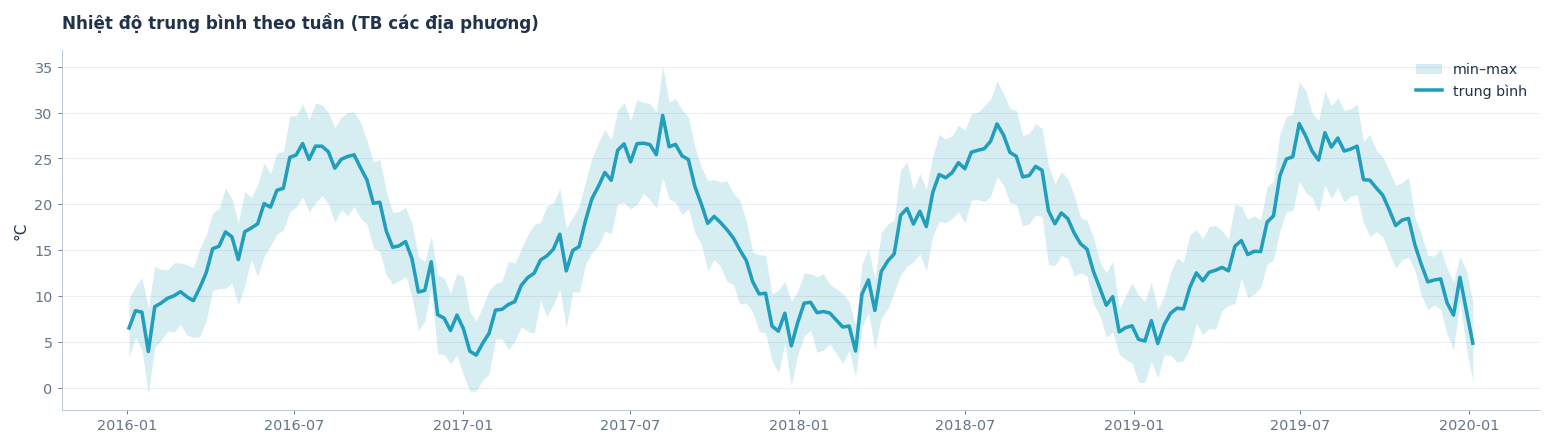

In [30]:
print('Số địa phương:', weather.locality.nunique(), '|', weather.date.min().date(), '→', weather.date.max().date())
print('Tỉ lệ thiếu theo cột (%):'); print((weather.isna().mean() * 100).round(2).to_string())
w = weather.groupby(pd.Grouper(key='date', freq='W'))[['avg temp °C', 'min temp °C', 'max temp °C']].mean()
fig, ax = plt.subplots(figsize=(14, 4))
ax.fill_between(w.index, w['min temp °C'], w['max temp °C'], color=MAIN, alpha=0.18, lw=0, label='min–max')
ax.plot(w.index, w['avg temp °C'], color=MAIN, label='trung bình')
ax.set_title('Nhiệt độ trung bình theo tuần (TB các địa phương)'); ax.set_ylabel('°C'); ax.legend(frameon=False)
plt.show()

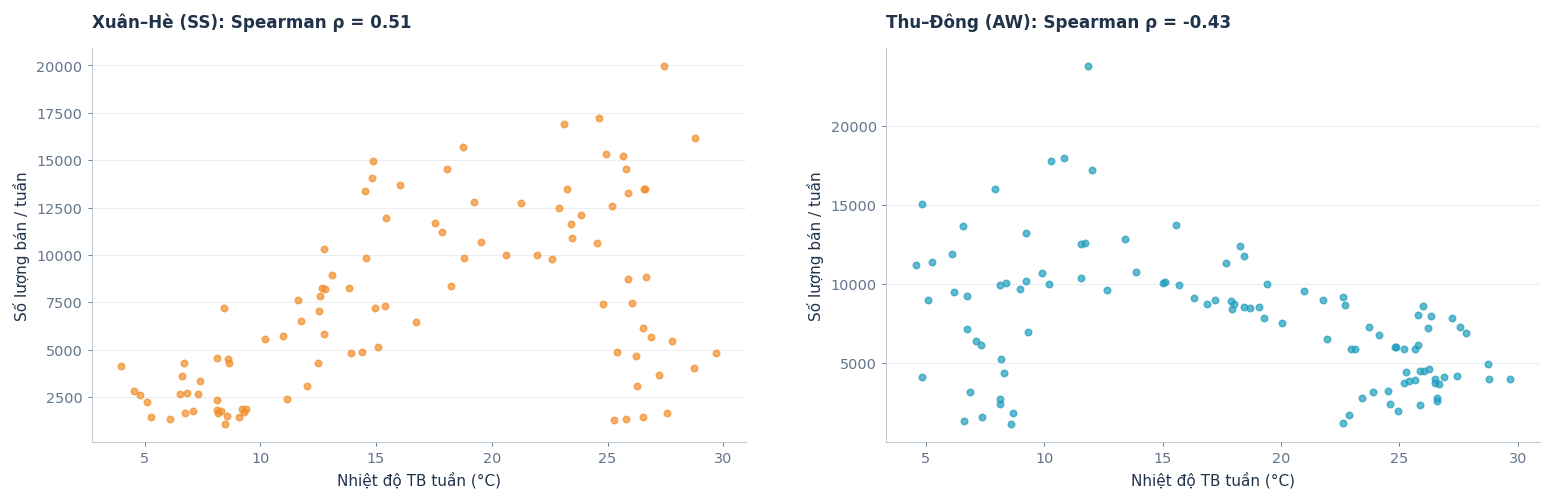

In [31]:
# Liên hệ nhiệt độ và doanh số theo tuần lịch (mùa SS vs AW)
long['season_type'] = long.external_code.map(sales.drop_duplicates('external_code').set_index('external_code').season.str[:2])
wk = long.groupby([pd.Grouper(key='date', freq='W'), 'season_type']).qty.sum().unstack()
wk = wk.join(w['avg temp °C'], how='inner')
# Chỉ giữ các tuần mà loại mùa đó thực sự đang bán (bỏ tuần ngoài mùa ~0)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, (st, lab, col) in zip(axes, [('SS', 'Xuân–Hè (SS)', PALETTE[1]), ('AW', 'Thu–Đông (AW)', MAIN)]):
    d = wk[wk[st] > 1000]
    ax.scatter(d['avg temp °C'], d[st], s=18, color=col, alpha=0.7)
    ax.set_xlabel('Nhiệt độ TB tuần (°C)'); ax.set_ylabel('Số lượng bán / tuần')
    ax.set_title(f'{lab}: Spearman ρ = {d["avg temp °C"].corr(d[st], method="spearman"):.2f}')
plt.tight_layout(); plt.show()

> ⚠️ Tương quan ở mức tổng hợp này **bị nhiễu** bởi lịch ra mắt và vòng đời sản phẩm. Khi ghép nhiệt độ theo từng cửa hàng (`shop_weather_pairs.pt`) và hiệu chỉnh theo tuần vòng đời (xem `Journal_Figures.ipynb`, Fig. 6b), tương quan gần như bằng 0 (ρ ≈ +0,005 với SS, +0,06 với AW). Doanh số chỉ tăng ở các tuần > 23 °C cho cả hai mùa — trùng với mùa sale hè hơn là do nhiệt độ.

## 8. Ảnh sản phẩm

{'AI17': 852, 'AI18': 944, 'AI19': 1054, 'PE17': 901, 'PE18': 758, 'PE19': 846}


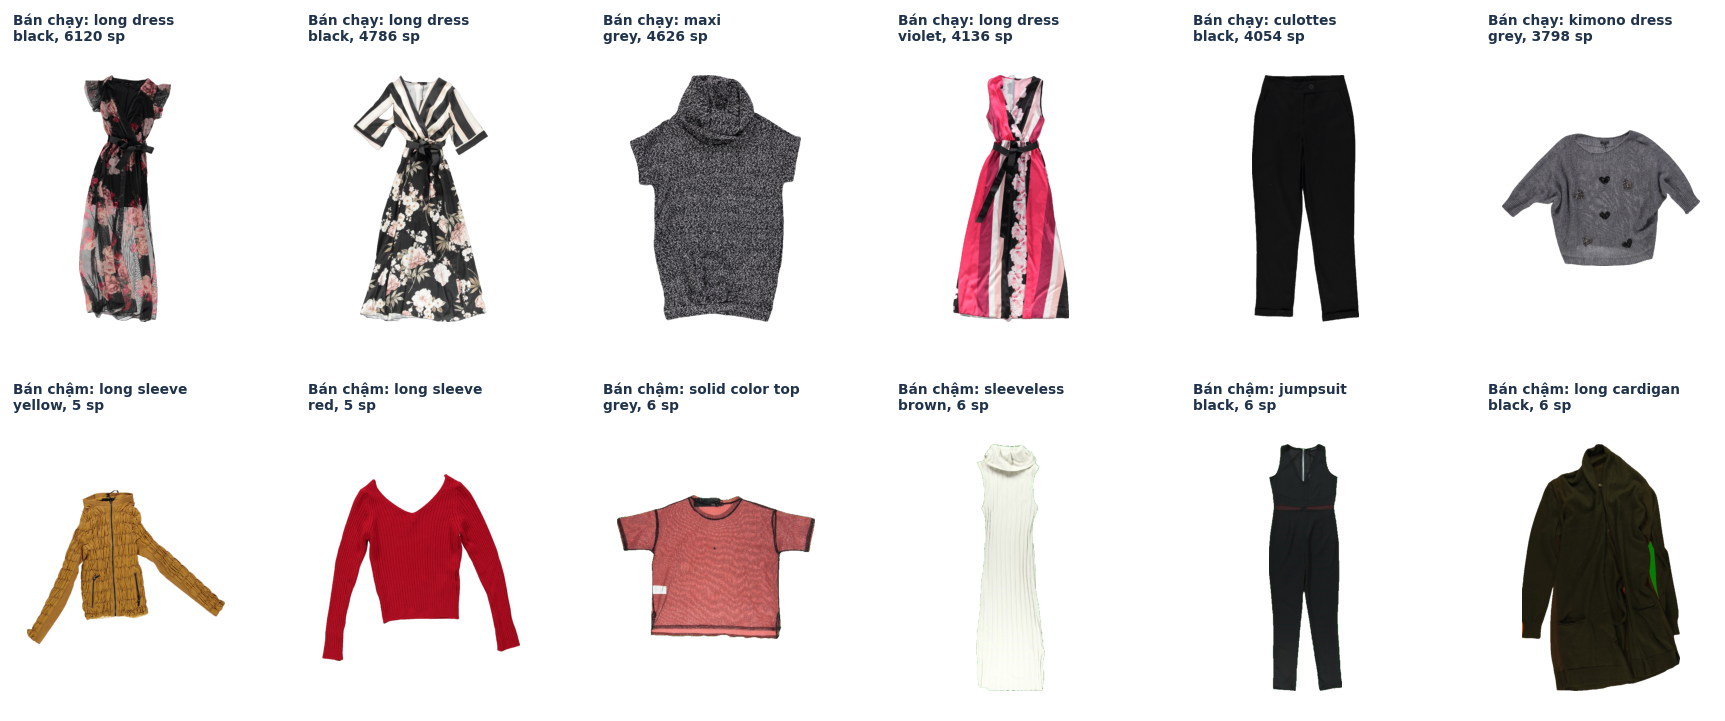

In [32]:
img_dir = DATA / 'images'
print({d.name: len(list(d.glob('*.png'))) for d in sorted(img_dir.iterdir())})
top_items = prod_sales.sort_values(ascending=False).head(6).index
bottom_items = prod_sales[prod_sales > 0].sort_values().head(6).index
info = products.set_index('external_code')
fig, axes = plt.subplots(2, 6, figsize=(16, 6.5))
for row, items, tag in [(0, top_items, 'Bán chạy'), (1, bottom_items, 'Bán chậm')]:
    for ax, code_ in zip(axes[row], items):
        im = Image.open(img_dir / info.loc[code_, 'image_path']).convert('RGBA')
        bg = Image.new('RGBA', im.size, 'white'); bg.alpha_composite(im)  # nền trong suốt → trắng
        ratio = im.width / im.height
        width = min(.88, ratio * 1.1); height = width / ratio
        ax.imshow(bg.convert('RGB'), extent=(.5-width/2, .5+width/2, .625-height/2, .625+height/2))
        ax.set_xlim(0, 1); ax.set_ylim(0, 1.25); ax.set_aspect('equal')
        ax.set_title(f'{tag}: {info.loc[code_, "category"]}\n{info.loc[code_, "color"]}, {int(prod_sales[code_])} sp', fontsize=9)
        ax.axis('off')
plt.tight_layout(); plt.show()

## 9. Tổng kết

### Chất lượng dữ liệu
- Các bảng chính **gần như không thiếu dữ liệu**: `sales` và `restocks` không có NaN; `price_discount` thiếu 1 ô; `customer_data` có 1 dòng trùng.
- `weather` thiếu ~3,8% ở mọi cột đo đạc (thiếu theo cả ngày) → cần nội suy / điền khi dùng.
- `sales` có ~3.400 ô bán **âm** theo tuần (≈0,26%) — nhiều khả năng là hàng trả lại; cần quyết định giữ hay cắt về 0 khi dự báo.
- `restocks` có bản ghi năm 2020–2022, nằm ngoài giai đoạn bán của các mùa SS17–AW19.
- `customer_data` phủ rộng hơn `sales` (129 vs 110 cửa hàng, 5.577 vs 5.355 SP, đến 06/2021) → khi ghép cần lọc theo phạm vi chung.

### Sản phẩm & doanh số
- 5.355 sản phẩm, 110 cửa hàng, 27 danh mục, 10 màu, 59 chất liệu; 106.850 cặp SP × cửa hàng với tổng 1,6 triệu sản phẩm bán ra trong 12 tuần đầu.
- Quy mô **tăng đều qua các mùa**: số cửa hàng 66 → 105 và tổng doanh số 195K → 337K từ SS17 đến AW19.
- Doanh số **lệch phải mạnh**: trung vị 152 sp/sản phẩm nhưng max 6.120; khoảng **36% sản phẩm tạo ra 80% doanh số**.
- **Vòng đời**: doanh số cao nhất ở tuần 0, giữ ổn định tuần 1–6 rồi giảm dần còn ~1/3 vào tuần 11.
- Danh mục lớn nhất về tổng doanh số là **culottes** và **long sleeve** (nhiều SP), nhưng hiệu quả trên mỗi SP cao nhất là **long dress, kimono dress, doll dress**.
- Doanh số / SP theo cửa hàng khá đồng đều (8–24); tổng doanh số cửa hàng chủ yếu do **số SP được phân phối** quyết định.

### Giá & khuyến mãi
- Giảm giá **tăng dần theo vòng đời**: TB ~2% ở tuần 0 lên ~24% ở tuần 11 (markdown cuối mùa).
- Mức giá (đã chuẩn hóa) gần như **không phân biệt** doanh số giữa các nhóm giá.
- Quan hệ giảm giá–doanh số yếu dương (ρ ≈ 0,07–0,20) và không đơn điệu → cần mô hình kiểm soát nhân quả ngược (SP bán chậm bị giảm giá sâu).

### Khách hàng
- 3,18 triệu dòng giao dịch, ~665 nghìn khách, ~1,76 triệu đơn; **98,5% dòng có qty = 1**, TB 1,84 món/đơn.
- **52,9% khách chỉ mua 1 lần** → tiềm năng lớn cho chương trình giữ chân khách.
- Mua sắm cao nhất vào **thứ Bảy**; theo giờ có 2 đỉnh **~11h** và **~17–18h**.
- Số đơn có đỉnh mùa vụ (tháng 7 và tháng 12–1 — mùa sale) và **giảm đột ngột từ 2020** (dữ liệu dừng sau AW19 / ảnh hưởng COVID-19).

### Dữ liệu ngoại sinh
- **Google Trends** thể hiện mùa vụ rõ (áo khoác dài ↑ mùa đông, short/cộc tay ↑ mùa hè) → feature tốt cho dự báo sản phẩm mới.
- **Thời tiết**: tương quan gộp theo tuần (SS ρ ≈ +0,51, AW ρ ≈ −0,43) **không còn** sau khi ghép theo cửa hàng và hiệu chỉnh vòng đời (ρ ≈ 0); chỉ thấy doanh số tăng ở các tuần nóng > 23 °C, nhiều khả năng do mùa sale hè → thời tiết không phải yếu tố giải thích mạnh ở mức tổng hợp.

### Gợi ý bước tiếp theo
1. Xử lý giá trị âm và dữ liệu thời tiết thiếu.
2. Ghép `sales` + `price_discount` + Google Trends + thời tiết (qua `shop_weather_pairs`) thành bảng feature.
3. Xây baseline dự báo doanh số 12 tuần cho sản phẩm mới (dùng sẵn split `stfore_train/test.csv`), có thể thêm đặc trưng ảnh.
4. Phân khúc khách hàng (RFM) từ `customer_data`.